In [1]:
# Cell 1: import library
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
# Cell 2: connect to MySQL
PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")
user = os.getenv("MYSQL_USER")
pwd = quote_plus(os.getenv("MYSQL_PASSWORD"))
host = os.getenv("MYSQL_HOST")
port = os.getenv("MYSQL_PORT")
db = os.getenv("MYSQL_DB")
engine = create_engine(f"mysql+pymysql://{user}:{pwd}@{host}:{port}/{db}")
with engine.connect() as conn:
    print("Current database:", conn.execute(text("SELECT DATABASE()")).scalar())

Current database: olist_ecommerce


In [3]:
# Cell 3: one row per customer, same definition as notebook 8, plus checks
q = """
SELECT customer_unique_id,
       MAX(order_purchase_timestamp) AS last_purchase,
       COUNT(*)                      AS frequency,
       SUM(revenue)                  AS monetary
FROM valid_orders_t
GROUP BY customer_unique_id
"""
cust = pd.read_sql(text(q), engine, parse_dates=["last_purchase"])
cust["monetary"] = cust["monetary"].astype(float)
cust = cust.sort_values("customer_unique_id").reset_index(drop=True)
ref_date = cust["last_purchase"].max().normalize() + pd.Timedelta(days=1)
cust["recency_days"] = (ref_date - cust["last_purchase"]).dt.total_seconds() / 86400

print("Reference date:", ref_date.date())   # expect 2018-09-04
checks = {
    "customers = 94982":       len(cust) == 94982,
    "orders = 98198":          int(cust["frequency"].sum()) == 98198,
    "revenue = 15738221.95":   round(cust["monetary"].sum(), 2) == 15738221.95,
    "repeat customers = 2887": int((cust["frequency"] > 1).sum()) == 2887,
}
for k, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", k)

Reference date: 2018-09-04
PASS - customers = 94982
PASS - orders = 98198
PASS - revenue = 15738221.95
PASS - repeat customers = 2887


In [4]:
# Cell 4: log-transform the skewed features, then standardize
feats = pd.DataFrame({
    "recency_days":  cust["recency_days"],
    "log_frequency": np.log1p(cust["frequency"]),
    "log_monetary":  np.log1p(cust["monetary"]),
})
print("Skewness before:", cust[["recency_days", "frequency", "monetary"]].skew().round(2).to_dict())
print("Skewness after: ", feats.skew().round(2).to_dict())

X = StandardScaler().fit_transform(feats)
print(X.shape, "mean ~", X.mean(axis=0).round(3), "std ~", X.std(axis=0).round(3))

Skewness before: {'recency_days': 0.45, 'frequency': 11.51, 'monetary': 9.11}
Skewness after:  {'recency_days': 0.45, 'log_frequency': 6.48, 'log_monetary': 0.53}
(94982, 3) mean ~ [ 0.  0. -0.] std ~ [1. 1. 1.]


,k,inertia,silhouette
0,2,193496.459,0.709
1,3,128517.893,0.360
2,4,87323.043,0.370
3,5,71634.930,0.357
4,6,60383.512,0.343
5,7,51659.928,0.355
6,8,45997.045,0.347


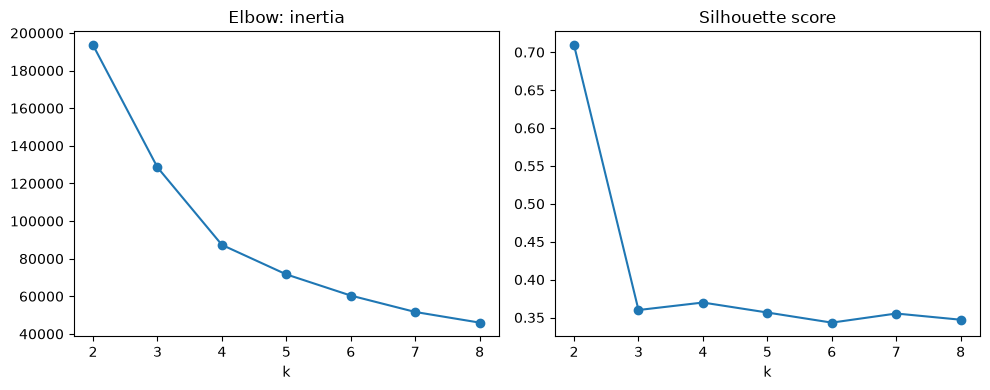

In [5]:
# Cell 5: elbow (inertia) and silhouette for k = 2..8 (silhouette on a 10,000-customer sample)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    sil = silhouette_score(X, km.labels_, sample_size=10000, random_state=42)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
ks = pd.DataFrame(rows)
display(ks.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ks["k"], ks["inertia"], marker="o")
axes[0].set_title("Elbow: inertia")
axes[0].set_xlabel("k")
axes[1].plot(ks["k"], ks["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [6]:
# Cell 6: how extreme is frequency after scaling, and compare feature sets A, B, C
z = (feats - feats.mean()) / feats.std()
print("share of customers with |z| > 3 (%):", ((z.abs() > 3).mean() * 100).round(2).to_dict())
print("max z-score:", z.max().round(1).to_dict())

sets = {
    "A: recency + log_freq + log_monetary": feats[["recency_days", "log_frequency", "log_monetary"]],
    "B: recency + log(freq capped at 3) + log_monetary": pd.DataFrame({
        "recency_days": cust["recency_days"],
        "capped_log_freq": np.log1p(cust["frequency"].clip(upper=3)),
        "log_monetary": feats["log_monetary"]}),
    "C: recency + log_monetary only": feats[["recency_days", "log_monetary"]],
}
rows = []
for name, F in sets.items():
    Xs = StandardScaler().fit_transform(F)
    for k in [3, 4, 5]:
        m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
        sizes = np.bincount(m.labels_) / len(Xs) * 100
        rows.append({"features": name, "k": k,
                     "silhouette": silhouette_score(Xs, m.labels_, sample_size=10000, random_state=42),
                     "smallest_cluster_pct": sizes.min(), "largest_cluster_pct": sizes.max()})
display(pd.DataFrame(rows).round(3))

share of customers with |z| > 3 (%): {'recency_days': 0.0, 'log_frequency': 3.04, 'log_monetary': 0.71}
max z-score: {'recency_days': 3.2, 'log_frequency': 27.6, 'log_monetary': 5.9}


,features,k,silhouette,smallest_cluster_pct,largest_cluster_pct
0,A: recency + log_freq + log_monetary,3,0.360,3.040,55.804
1,A: recency + log_freq + log_monetary,4,0.370,3.040,38.487
2,A: recency + log_freq + log_monetary,5,0.357,3.040,31.336
3,B: recency + log(freq capped at 3) + log_monetary,3,0.361,3.040,55.635
4,B: recency + log(freq capped at 3) + log_monetary,4,0.371,3.040,38.261
5,B: recency + log(freq capped at 3) + log_monetary,5,0.357,3.040,30.792
6,C: recency + log_monetary only,3,0.361,29.637,39.278
7,C: recency + log_monetary only,4,0.347,12.843,32.462
8,C: recency + log_monetary only,5,0.334,9.982,31.580


Skewness: {'recency_days': 0.45, 'log_monetary': 0.53}


,k,inertia,silhouette,smallest_cluster_pct
0,2,123140.338,0.347,42.407
1,3,79524.290,0.361,29.637
2,4,63222.326,0.347,12.843
3,5,51454.218,0.334,9.982
4,6,42466.274,0.346,9.848
5,7,36663.700,0.337,8.264
6,8,32546.146,0.336,4.954


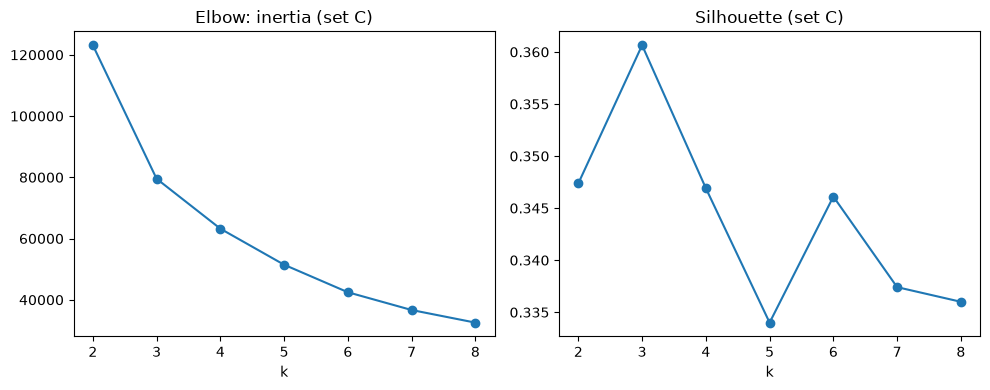

In [7]:
# Cell 7: final feature set C (recency + log monetary) and choice of k (2..8)
feats_c = pd.DataFrame({
    "recency_days": cust["recency_days"],
    "log_monetary": np.log1p(cust["monetary"]),
})
print("Skewness:", feats_c.skew().round(2).to_dict())
X_c = StandardScaler().fit_transform(feats_c)

rows = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_c)
    rows.append({"k": k, "inertia": m.inertia_,
                 "silhouette": silhouette_score(X_c, m.labels_, sample_size=10000, random_state=42),
                 "smallest_cluster_pct": np.bincount(m.labels_).min() / len(X_c) * 100})
ks_c = pd.DataFrame(rows)
display(ks_c.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ks_c["k"], ks_c["inertia"], marker="o")
axes[0].set_title("Elbow: inertia (set C)")
axes[0].set_xlabel("k")
axes[1].plot(ks_c["k"], ks_c["silhouette"], marker="o")
axes[1].set_title("Silhouette (set C)")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [8]:
# Cell 8: final model on set C, cluster profile, and stability across random seeds
from sklearn.metrics import adjusted_rand_score

K = 4   # change after reading Cell 7
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_c)
cust["cluster"] = km.labels_

prof = cust.groupby("cluster").agg(
    customers=("customer_unique_id", "size"),
    revenue=("monetary", "sum"),
    avg_recency_days=("recency_days", "mean"),
    avg_orders=("frequency", "mean"),
    repeat_share_pct=("frequency", lambda s: (s > 1).mean() * 100),
    avg_spend=("monetary", "mean"),
    median_spend=("monetary", "median"),
)
prof["customer_share_pct"] = prof["customers"] / prof["customers"].sum() * 100
prof["revenue_share_pct"] = prof["revenue"] / prof["revenue"].sum() * 100
prof = prof.sort_values("revenue", ascending=False).round(2)
display(prof)

print("PASS" if prof["customers"].sum() == 94982 else "FAIL", "- clusters cover 94982 customers")
print("PASS" if round(prof["revenue"].sum(), 2) == 15738221.95 else "FAIL", "- cluster revenue = 15738221.95")

aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit(X_c).labels_)
        for s in [1, 2, 3, 4, 5]]
print("Adjusted Rand index vs seed 42 (1.0 = identical):", np.round(aris, 3))

,customers,revenue,avg_recency_days,avg_orders,repeat_share_pct,avg_spend,median_spend,customer_share_pct,revenue_share_pct
cluster,,,,,,,,,
3,12199,6603361.47,273.90,1.11,8.69,541.30,399.00,12.84,41.96
0,30833,4976795.17,137.38,1.04,3.96,161.41,146.69,32.46,31.62
1,26062,2769020.20,431.25,1.02,1.89,106.25,94.30,27.44,17.59
2,25888,1389045.11,167.27,1.00,0.44,53.66,53.35,27.26,8.83


PASS - clusters cover 94982 customers
PASS - cluster revenue = 15738221.95
Adjusted Rand index vs seed 42 (1.0 = identical): [0.989 0.907 0.998 0.993 0.939]


In [9]:
# Cell 9: recompute the notebook 8 segments and compare them with the K-Means clusters
from sklearn.metrics import adjusted_rand_score

cust["R"] = pd.qcut(cust["recency_days"].rank(method="first", ascending=False), 5, labels=[1, 2, 3, 4, 5]).astype(int)
cust["M"] = pd.qcut(cust["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
cust["F"] = np.select([cust["frequency"] == 1, cust["frequency"] == 2], [1, 2], default=3)

conds = [
    (cust["F"] >= 2) & (cust["R"] >= 4),
    (cust["F"] >= 2),
    (cust["R"] >= 4) & (cust["M"] >= 4),
    (cust["R"] >= 4),
    (cust["M"] >= 4),
]
names = ["Champions", "Repeat but lapsing", "Recent high spenders", "Recent customers", "Lapsed high spenders"]
cust["segment"] = np.select(conds, names, default="Lapsed low spenders")

print("PASS" if (cust["segment"] == "Lapsed high spenders").sum() == 21050 else "FAIL",
      "- Lapsed high spenders = 21050 (same as notebook 8)")

counts = pd.crosstab(cust["cluster"], cust["segment"])
display(counts)
display((counts.div(counts.sum(axis=1), axis=0) * 100).round(1))   # each row sums to 100
print("Adjusted Rand index, K-Means vs rule-based:",
      round(adjusted_rand_score(cust["cluster"], cust["segment"]), 3))

PASS - Lapsed high spenders = 21050 (same as notebook 8)


segment,Champions,Lapsed high spenders,Lapsed low spenders,Recent customers,Recent high spenders,Repeat but lapsing
cluster,,,,,,
0,864,5786,3608,8290,11928,357
1,0,6845,18725,0,0,492
2,65,0,11958,13816,0,49
3,310,8419,0,0,2720,750


segment,Champions,Lapsed high spenders,Lapsed low spenders,Recent customers,Recent high spenders,Repeat but lapsing
cluster,,,,,,
0,2.8,18.8,11.7,26.9,38.7,1.2
1,0.0,26.3,71.8,0.0,0.0,1.9
2,0.3,0.0,46.2,53.4,0.0,0.2
3,2.5,69.0,0.0,0.0,22.3,6.1


Adjusted Rand index, K-Means vs rule-based: 0.249


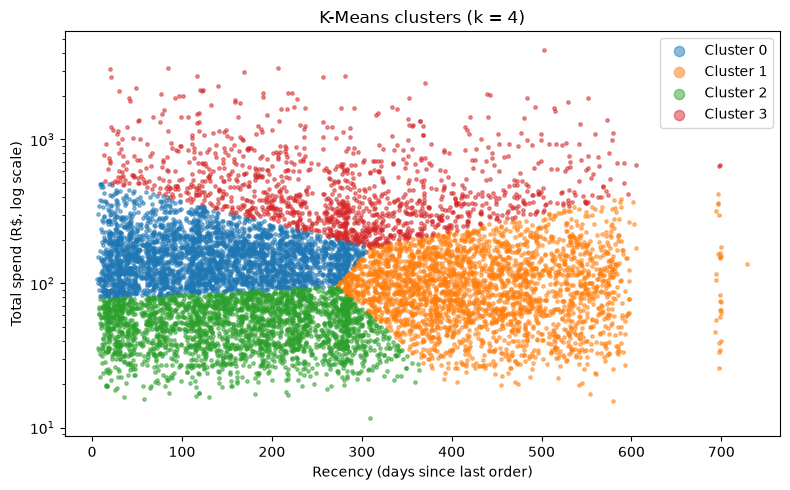

In [10]:
# Cell 10: recency vs total spend for a 10,000-customer sample, coloured by cluster
sample = cust.sample(10000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 5))
for c, g in sample.groupby("cluster"):
    ax.scatter(g["recency_days"], g["monetary"], s=6, alpha=0.5, label=f"Cluster {c}")
ax.set_yscale("log")
ax.set_xlabel("Recency (days since last order)")
ax.set_ylabel("Total spend (R$, log scale)")
ax.set_title("K-Means clusters (k = 4)")
ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

## Skewness handling and feature decision

K-Means uses distances between customers, so a feature with a long tail or extreme values can dominate the clusters. All three features were checked for skewness before clustering.

### Skewness of each feature
| Feature | Skewness (raw) | Skewness (after log) | Decision |
|---|---|---|---|
| Recency (days) | 0.45 | not needed | Kept as it is. It is already close to symmetric (skewness well within ±1). |
| Monetary (total spend) | 9.11 | 0.53 | `log(1 + x)` applied and kept. A few customers spend up to R$13,664, and the log compresses that tail. |
| Frequency (orders) | 11.51 | 6.48 | **Not used for clustering.** See below. |

### Why frequency could not be fixed by a transform
- 92,095 of 94,982 customers (97%) have exactly 1 order, so almost all values are tied. A log transform keeps tied values tied, so skewness stays high (6.48) after the log.
- After standardization, 3.04% of customers had |z| > 3 on frequency, and the maximum z-score was 27.6. For recency it was 3.2 and for log monetary 5.9. The 3.04% equals the repeat-customer share (2,887 of 94,982).

### Evidence from the feature-set comparison (Cell 6)
- **A** (recency + log frequency + log monetary) and **B** (frequency capped at 3 orders): the smallest cluster was exactly 3.04% for k = 3, 4 and 5. That cluster is the repeat buyers, and raising k only split the one-time buyers. At k = 4 the silhouette was 0.370 for A and 0.371 for B, so capping the tail changed almost nothing.
- **C** (recency + log monetary only): the smallest cluster at k = 4 was 12.8% and the largest 32.5%, so the clusters are balanced.
- Silhouette scores are not compared across the sets, because each set has a different number of dimensions. The sets were judged by cluster sizes and by whether the clusters can be explained.

### Decision
Cluster on **recency and log(1 + total spend)** (standardized). Frequency is reported as a profile column (share of repeat customers in each cluster), and the rule-based segments in notebook 8 already cover it with fixed bands (1, 2 and 3+ orders).

### What this costs
Frequency does not take part in forming the clusters, so repeat buyers are spread over all four clusters. This is stated in the final findings.

## Customer segmentation findings

**Data:** 94,982 customers (by customer_unique_id) from valid sales, R$15,738,221.95 in total, reference date 2018-09-04. All totals reconcile with notebooks 6 and 8.

### Method
- **Algorithm:** K-Means on standardized features, `n_init = 10`, `random_state = 42`.
- **Features:** recency (days since last order) and log(1 + total spend). Frequency is not a feature: 92,095 customers (97%) ordered once, so after scaling the 3.04% repeat buyers sat up to 27.6 standard deviations from the rest. In the test, the smallest cluster was exactly 3.04% (the repeat buyers) for k = 3, 4 and 5, and capping frequency at 3 changed nothing. Without frequency the smallest cluster was 12.8% at k = 4. Frequency is shown as a profile column (repeat share) instead.
- **Choice of k = 4:** the silhouette is close to flat (0.334 to 0.361 for k = 2 to 8) and the elbow is gradual, so k = 4 was chosen as the point where the elbow bends, giving clusters that are balanced (smallest 12.8%) and interpretable.
- **Stability:** adjusted Rand index between the seed 42 clusters and five other seeds is 0.907 to 0.998.

### Clusters
| Cluster | Name | Customers | Revenue share | Avg recency (days) | Avg spend | Repeat share |
|---|---|---|---|---|---|---|
| 3 | High spenders | 12,199 (12.84%) | 41.96% | 274 | R$541.30 | 8.69% |
| 0 | Recent mid spenders | 30,833 (32.46%) | 31.62% | 137 | R$161.41 | 3.96% |
| 1 | Long-lapsed mid-to-low spenders | 26,062 (27.44%) | 17.59% | 431 | R$106.25 | 1.89% |
| 2 | Low spenders | 25,888 (27.26%) | 8.83% | 167 | R$53.66 | 0.44% |

### Findings
- **A small group carries the revenue.** The 12,199 high spenders (12.84% of customers) bring 41.96% of revenue; their median spend is R$399.00 and their average R$541.30.
- **High spenders also have the most repeat buyers** (8.69% against 3.04% overall), but even in this cluster over 91% ordered only once.
- **The largest recent group is mid-range.** Cluster 0 is the most recent (137 days on average) and brings 31.62% of revenue, so it is the group most likely to order again soon.
- **Long-lapsed customers are about a quarter of the base.** Cluster 1 last ordered about 431 days before the reference date and brings 17.59% of revenue.
- **Low spenders add little.** Cluster 2 is 27.26% of customers and 8.83% of revenue, with an average spend of R$53.66 and almost no repeat buyers (0.44%).

### Comparison with the rule-based RFM segments (notebook 8)
- The two methods agree only partly (adjusted Rand index 0.249), because the rules also use frequency and fixed quintile cutoffs, while K-Means uses recency and spend only.
- They tell a consistent story: cluster 3 is 69.0% lapsed high spenders and 22.3% recent high spenders, cluster 1 is 71.8% lapsed low spenders, and cluster 2 contains no high spenders.
- K-Means isolates a narrower, richer top group (12.8% of customers, 42.0% of revenue) than the rule-based high spenders (37.6% of customers, 68.3% of revenue), whose cutoff is lower (about R$133).
- Repeat buyers are spread over all four clusters, since frequency is not used.

### Limits
- The silhouette score (about 0.35) shows overlapping clusters. The segments split a continuous range of customers and are not natural groups, and the boundaries are not sharp.
- K-Means assumes roughly round clusters of similar size, and the results depend on the log transform of spend.
- The data ends in September 2018, so "long-lapsed" may include customers who had not had time to return. A small group last ordered around October 2016, early in the dataset.
- Cluster names are descriptive labels based on the averages above, not categories in the data.